In [1]:
print("Python is working!")

Python is working!


# 1. Load and understand the dataset

In [2]:
from datasets import load_dataset

ds = load_dataset("stanfordnlp/imdb")

print(ds)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [3]:
print(ds)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [4]:
# Check the available splits
print(ds.keys())



dict_keys(['train', 'test', 'unsupervised'])


In [5]:
# Check the training dataset size
print(len(ds["train"]))



25000


In [ ]:
# Display one movie review
print(ds["train"][0]["text"])



I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far between, eve

In [9]:
# Display its sentiment label
print(ds["train"][0]["label"])

0


#### The dataset has 25,000 training reviews, 25,000 testing reviews, and 50,000 additional unlabeled reviews.

# 2 Check the dataset structure

In [10]:
# Display the available splits
print(ds.keys())

# Display the number of records in each split
print("Training records:", len(ds["train"]))
print("Testing records:", len(ds["test"]))
print("Unsupervised records:", len(ds["unsupervised"]))

# Display column names
print(ds["train"].column_names)

dict_keys(['train', 'test', 'unsupervised'])
Training records: 25000
Testing records: 25000
Unsupervised records: 50000
['text', 'label']


In [11]:
print(ds["test"].column_names)

['text', 'label']


In [12]:
print(ds["unsupervised"].column_names)

['text', 'label']


#### The two columns mean:
- text: the actual movie review.
- label: the sentiment category, where 0 means negative and 1 means positive.
The unsupervised split has no sentiment labels useful for ordinary supervised training, so we will use the labeled training and testing splits first.

# 3. Display sample movie reviews

In [13]:
print(ds["train"][0])

{'text': 'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far be

In [16]:
# To display the review and its sentiment separately:

review = ds["train"][0]['text']
label = ds['train'][0]['label']

print("Movie Review:", review)

print("\nSentiment Label:", label)

if label == 0:
    print("Sentiment: Negative")

else:
    print("Sentiment: Positive")

Movie Review: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and fa

In [21]:
# To display the review and its sentiment separately:

review = ds["train"][10]['text']
label = ds['train'][10]['label']

print("Movie Review:", review)

print("\nSentiment Label:", label)

if label == 0:
    print("Sentiment: Negative")

else:
    print("Sentiment: Positive")

Movie Review: It was great to see some of my favorite stars of 30 years ago including John Ritter, Ben Gazarra and Audrey Hepburn. They looked quite wonderful. But that was it. They were not given any characters or good lines to work with. I neither understood or cared what the characters were doing.<br /><br />Some of the smaller female roles were fine, Patty Henson and Colleen Camp were quite competent and confident in their small sidekick parts. They showed some talent and it is sad they didn't go on to star in more and better films. Sadly, I didn't think Dorothy Stratten got a chance to act in this her only important film role.<br /><br />The film appears to have some fans, and I was very open-minded when I started watching it. I am a big Peter Bogdanovich fan and I enjoyed his last movie, "Cat's Meow" and all his early ones from "Targets" to "Nickleodeon". So, it really surprised me that I was barely able to keep awake watching this one.<br /><br />It is ironic that this movie is 

# 4. Convert the dataset into Pandas DataFrames

In [22]:
ds['train']

Dataset({
    features: ['text', 'label'],
    num_rows: 25000
})

In [23]:
import pandas as pd

train_df = ds['train'].to_pandas()
test_df = ds['test'].to_pandas()

In [24]:
train_df

,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0
...,...,...
24995,A hit at the time but now better categorised a...,1
24996,I love this movie like no other. Another time ...,1
24997,This film and it's sequel Barry Mckenzie holds...,1
24998,'The Adventures Of Barry McKenzie' started lif...,1


In [25]:
test_df

,text,label
0,I love sci-fi and am willing to put up with a ...,0
1,"Worth the entertainment value of a rental, esp...",0
2,its a totally average film with a few semi-alr...,0
3,STAR RATING: ***** Saturday Night **** Friday ...,0
4,"First off let me say, If you haven't enjoyed a...",0
...,...,...
24995,Just got around to seeing Monster Man yesterda...,1
24996,I got this as part of a competition prize. I w...,1
24997,I got Monster Man in a box set of three films ...,1
24998,"Five minutes in, i started to feel how naff th...",1


In [26]:
print(train_df.head())

                                                text  label
0  I rented I AM CURIOUS-YELLOW from my video sto...      0
1  "I Am Curious: Yellow" is a risible and preten...      0
2  If only to avoid making this type of film in t...      0
3  This film was probably inspired by Godard's Ma...      0
4  Oh, brother...after hearing about this ridicul...      0


In [28]:
print(train_df.shape)

(25000, 2)


In [30]:
print(test_df.shape)

(25000, 2)


In [33]:
# check missing values

print(train_df.isnull().sum())

text     0
label    0
dtype: int64


# 5. Perform Exploratory Data Analysis (EDA)

In [40]:
# check how many positive and negative reviews exist.

print(train_df["label"].value_counts())

label
0    12500
1    12500
Name: count, dtype: int64


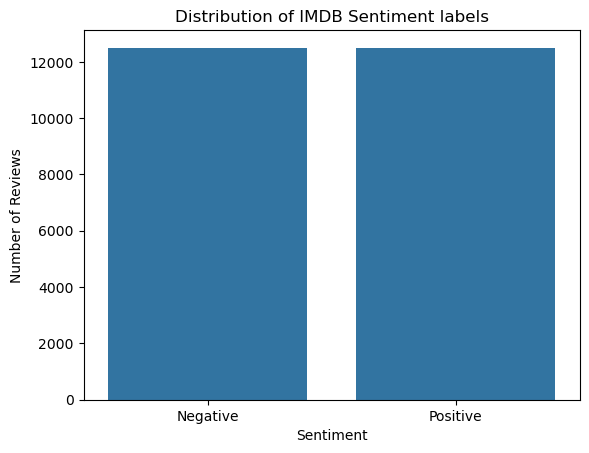

In [37]:
import matplotlib.pyplot as plt

import seaborn as sns

sns.countplot(data = train_df, x = 'label')

plt.xticks([0,1], ['Negative', 'Positive'])
plt.title("Distribution of IMDB Sentiment labels")
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()

In [41]:
train_df['review_length'] = train_df['text'].str.len()
print(train_df['review_length'].describe())

count    25000.00000
mean      1325.06964
std       1003.13367
min         52.00000
25%        702.00000
50%        979.00000
75%       1614.00000
max      13704.00000
Name: review_length, dtype: float64


# 6. Preprocess the text

In [42]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<br\s*/?>", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

train_df['clean_text'] = train_df['text'].apply(clean_text)
test_df['clean_text'] = test_df['text'].apply(clean_text)

print(train_df[['text', 'clean_text']].head())

                                                text  \
0  I rented I AM CURIOUS-YELLOW from my video sto...   
1  "I Am Curious: Yellow" is a risible and preten...   
2  If only to avoid making this type of film in t...   
3  This film was probably inspired by Godard's Ma...   
4  Oh, brother...after hearing about this ridicul...   

                                          clean_text  
0  i rented i am curious-yellow from my video sto...  
1  "i am curious: yellow" is a risible and preten...  
2  if only to avoid making this type of film in t...  
3  this film was probably inspired by godard's ma...  
4  oh, brother...after hearing about this ridicul...  


# 7. Convert text into numerical features using TF-IDF

In [44]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1,2),
    min_df=2
)

X_train = vectorizer.fit_transform(train_df['clean_text'])
X_test = vectorizer.transform(test_df['clean_text'])

y_train = train_df['label']
y_test = test_df['label']

print("Training feature shape:", X_train.shape)
print("Testing featire shape:", X_test.shape)

Training feature shape: (25000, 20000)
Testing featire shape: (25000, 20000)


### What happens here?
- max_features=20000: uses at most 20,000 vocabulary features.
- ngram_range=(1, 2): considers individual words and two-word phrases.
- min_df=2: ignores features appearing in fewer than two training documents.
- fit_transform(): learns the vocabulary and transforms training text.
- transform(): transforms test text using the training vocabulary.
Important: We fit TF-IDF only on training data to avoid leaking information from the test set.

# 8. Train your first machine learning model

In [47]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

print("Model training completed")

# The model learns patterns in movie reviews that help distinguish positive from negative sentiment.

Model training completed


# 9. Evaluate model performance

In [48]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.895

Classification Report:
              precision    recall  f1-score   support

    Negative       0.90      0.89      0.89     12500
    Positive       0.89      0.90      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.89     25000
weighted avg       0.90      0.90      0.89     25000


Confusion Matrix:
[[11145  1355]
 [ 1270 11230]]


### you will obtain the following metrics:
- Accuracy: percentage of reviews classified correctly.
- Precision: how many predictions for a sentiment class were correct.
- Recall: how many actual examples of that class were identified.
- F1-score: a combined measure of precision and recall.

# 10. Test your own movie reviews

In [50]:
def predict_sentiment(review):
    cleaned_review = clean_text(review)

    review_vector = vectorizer.transform([cleaned_review])

    prediction = model.predict(review_vector)[0]

    if prediction ==1:
        return 'Positive'
    else:
        return 'Negative'

print(predict_sentiment("This movie was amazing, with excellent acting and a great story."))
print(predict_sentiment("The movie was boring, poorly acted, and a complete waste of time."))

Positive
Negative


# 11. Save the trained model

In [51]:
import joblib

joblib.dump(model, "imdb_sentiment_model.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!
